# Poker Tilt: Agent-Based Simulation with Ground Truth

Real hand histories never say *when* a player was tilting, so on real data we can only show that flags rise after
losses. This notebook builds simulated players whose tilt we control, plays full No-Limit Hold'em games with them,
runs **the same detection pipeline** as `PokerTilt.ipynb`, and scores it against the true answers.

1. Hand strength (how agents judge their cards)
2. Players (styles, consistency, tilt-proneness)
3. The tilt model (the ground truth)
4. Decisions and bet sizing (human-like behavior)
5. Playing sessions (PokerKit engine)
6. Run the simulation
7. Realism check against the real data
8. Detection pipeline (same steps as `PokerTilt.ipynb`)
9. Results against the ground truth (including a bet-level breakdown)
10. How detection depends on tilt strength
11. Limitations
12. Save

Runtime: about 8–10 minutes in Colab (most of it is simulating hands).

In [1]:
!pip install -q pokerkit

In [2]:
import warnings, time, itertools, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pokerkit import Automation, NoLimitTexasHoldem, Mode
warnings.filterwarnings('ignore')

## 1. Hand strength

Agents decide from how strong their hand is, on a 0–1 scale:

- **Preflop:** the Chen formula, a standard way to rank starting hands, turned into a percentile
  (0.9 = better than 90% of starting hands).
- **After the flop:** the made hand (pair, two pair, set, straight, …) adjusted for how it compares to the board
  (top pair vs. weak pair, overpair), plus a bonus for flush and straight draws before the river.

This value is **hidden** from the dataset, just like real players' hole cards.

In [3]:
# ---- settings
SB, BB = 50, 100                  # chips; 1 bb = 100 chips
START_STACK = 100 * BB
AUTOMATIONS = tuple(Automation)   # PokerKit deals, collects bets, shows down and pays out

RANKS = '23456789TJQKA'
RV = {r: i + 2 for i, r in enumerate(RANKS)}


def card(c):
    return RV[c.rank.value], c.suit.value


# ---- preflop strength (Chen formula -> percentile)
def chen(r1, r2, suited):
    hi, lo = max(r1, r2), min(r1, r2)
    pts = {14: 10, 13: 8, 12: 7, 11: 6}.get(hi, hi / 2)
    if hi == lo:
        return max(5, pts * 2)
    gap = hi - lo - 1
    pts += 2 if suited else 0
    pts -= [0, 1, 2, 4][gap] if gap < 4 else 5
    if gap <= 1 and hi < 12:
        pts += 1
    return pts


_combos = [(a, b, s) for a in range(2, 15) for b in range(2, a + 1) for s in ([False] if a == b else [True, False])]
_weights = [6 if a == b else (4 if s else 12) for a, b, s in _combos]
_scores = np.array([chen(a, b, s) for a, b, s in _combos])
_order = np.argsort(_scores, kind='stable')
_cum = np.cumsum(np.array(_weights)[_order]) / sum(_weights)
PREFLOP_PCT = {}
for rank_pos, idx in enumerate(_order):
    PREFLOP_PCT[_combos[idx]] = _cum[rank_pos]   # share of hands this one beats or ties


def preflop_strength(hole):
    (r1, s1), (r2, s2) = card(hole[0]), card(hole[1])
    a, b = max(r1, r2), min(r1, r2)
    return PREFLOP_PCT[(a, b, s1 == s2 and a != b)]


# ---- postflop strength (made hand + draws, 0..1)
def _straight_high(ranks):
    rs = set(ranks)
    if 14 in rs:
        rs.add(1)
    for top in range(14, 4, -1):
        if all(r in rs for r in range(top - 4, top + 1)):
            return top
    return 0


def postflop_strength(hole, board):
    h = [card(c) for c in hole]
    b = [card(c) for c in board]
    allc = h + b
    hr = [r for r, _ in h]
    br = sorted([r for r, _ in b], reverse=True)
    ranks = [r for r, _ in allc]
    cnt = {r: ranks.count(r) for r in set(ranks)}
    bcnt = {r: br.count(r) for r in set(br)}
    suits = [s for _, s in allc]

    # flush / straight that use a hole card
    flush = any(suits.count(s) >= 5 and any(hs == s for _, hs in h) for s in set(suits))
    straight = _straight_high(ranks) > _straight_high(br)
    quads = any(c >= 4 and (r in hr) for r, c in cnt.items())
    trips_r = [r for r, c in cnt.items() if c >= 3 and r in hr]
    pairs_r = [r for r, c in cnt.items() if c >= 2]
    full = bool(trips_r) and len(pairs_r) >= 2

    if quads or (flush and straight):
        s = 0.99
    elif full:
        s = 0.96
    elif flush:
        s = 0.92
    elif straight:
        s = 0.88
    elif trips_r:
        s = 0.86 if hr[0] == hr[1] else 0.78          # set vs trips with a board pair
    else:
        hole_pairs = [r for r in pairs_r if r in hr]
        if len(hole_pairs) >= 2:
            s = 0.76                                     # two pair using both hole cards
        elif hr[0] == hr[1] and hr[0] > br[0]:
            s = 0.70 + 0.04 * (hr[0] >= 13)              # overpair
        elif hole_pairs:
            pr = hole_pairs[0]
            kicker = max(r for r in hr if r != pr) if hr[0] != hr[1] else pr
            if pr == br[0]:
                s = 0.58 + 0.06 * (kicker >= 12)         # top pair
            elif len(br) > 1 and pr >= br[1]:
                s = 0.44                                 # second pair
            else:
                s = 0.32                                 # weak pair
            if any(c >= 2 for c in bcnt.values()):
                s += 0.06                                # pair + board pair = two pair
        else:
            s = 0.06 + 0.08 * (max(hr) > br[0]) + 0.02 * (max(hr) >= 13)   # high card

    # draws (only before the river)
    if len(b) < 5 and s < 0.85:
        if any(suits.count(sv) == 4 and any(hs == sv for _, hs in h) for sv in set(suits)):
            s += 0.18
        rs = set(ranks) | ({1} if 14 in ranks else set())
        oesd = any(all(r in rs for r in range(lo, lo + 4)) and lo + 4 <= 14 and lo >= 2 for lo in range(1, 12))
        if oesd:
            s += 0.10
    return min(s, 0.99)

## 2. Players

Each player is drawn from a common poker archetype, then given their own random values within that archetype's range:

| Archetype | Share | Style |
|---|---|---|
| TAG (tight-aggressive) | 35% | plays few hands, bets them hard |
| LAG (loose-aggressive) | 15% | plays many hands aggressively |
| Nit | 15% | very tight and cautious |
| Station | 25% | plays and calls a lot, rarely raises |
| Maniac | 10% | plays most hands, bets and raises constantly |

Per-player settings:
- `vpip`: share of hands played voluntarily
- `aggression`: how often they bet or raise instead of calling
- `open_bb`, `bet_frac`: usual preflop open size (in bb) and postflop bet (as a fraction of the pot)
- `consistency`: random spread of bet sizes (log scale); higher = less consistent
- `strength_tell`: how much bet size grows with (hidden) hand strength; some players bet big with strong hands, some do the reverse
- **`tilt_score`** (0–1): how easily they tilt. About a third of players never tilt (0).

In [4]:
# ---- players
ARCHETYPES = {
    #            share  vpip         aggression   open (bb)    bet % pot     consistency (log-sd)
    'TAG':      (0.35, (0.20, 0.27), (0.60, 0.75), (2.5, 3.2), (0.55, 0.75), (0.15, 0.30)),
    'LAG':      (0.15, (0.30, 0.40), (0.70, 0.85), (3.0, 4.0), (0.65, 0.95), (0.20, 0.35)),
    'Nit':      (0.15, (0.12, 0.17), (0.40, 0.60), (2.5, 3.0), (0.50, 0.65), (0.10, 0.20)),
    'Station':  (0.25, (0.40, 0.60), (0.15, 0.35), (2.0, 4.0), (0.40, 1.00), (0.30, 0.50)),
    'Maniac':   (0.10, (0.50, 0.70), (0.85, 0.95), (3.0, 6.0), (0.80, 1.30), (0.35, 0.55)),
}


def make_players(n, rng):
    names = list(ARCHETYPES)
    shares = np.array([ARCHETYPES[k][0] for k in names])
    rows = []
    for i in range(n):
        arch = rng.choice(names, p=shares / shares.sum())
        _, vp, ag, op, bf, co = ARCHETYPES[arch]
        tilt = 0.0 if rng.random() < 0.35 else rng.uniform(0.1, 1.0)   # about a third never tilt
        rows.append(dict(player=f'sim{i:03d}', archetype=arch,
                         vpip=rng.uniform(*vp), aggression=rng.uniform(*ag),
                         open_bb=rng.uniform(*op), bet_frac=rng.uniform(*bf), consistency=rng.uniform(*co),
                         strength_tell=rng.uniform(-1.0, 3.0),   # how much bet size grows with hand strength (hidden)
                         tilt_score=tilt))
    return pd.DataFrame(rows).set_index('player')

## 3. The tilt model (ground truth)

Each player carries a hidden **tilt level T** during a session (starts at 0):

- After a hand where they **lose more than 20 bb**, T rises by `tilt_score × (loss / 50 bb)`, capped at 1.5 × `tilt_score`.
- A **bad beat** (losing after holding a strong hand, strength > 0.8) adds another `0.5 × tilt_score`.
- T **fades by 30% every hand** (half-life about 2 hands), and resets between sessions.
- **Loss chasing:** being down in the session adds a small extra amount (up to `0.2 × tilt_score` when down 75+ bb).

While tilted, a player:
- bets bigger: sizes are multiplied by `exp(TILT_SIZE × T)` (T = 1 → about 1.4×);
- sizes less consistently (more noise);
- plays more hands and bluffs more often.

**Ground-truth label:** a bet is `tilted` when T ≥ 0.30. Only the bigger bet sizes are visible to the detector; the
looser play and extra bluffs are tilt it is *not designed* to catch, which keeps the test honest.

In [5]:
# ---- tilt model (the ground truth)
TILT_SIZE = 0.35      # bet-size multiplier = exp(TILT_SIZE * T)  -> T = 1 gives about 1.4x
TILT_DECAY = 0.70     # T shrinks by 30% every hand (half-life about 2 hands)
LOSS_TRIGGER = 20     # losses bigger than 20 bb raise T
TILTED_CUTOFF = 0.30  # a bet counts as "tilted" when T >= 0.30 (bets at least ~11% bigger)

## 4. Decisions and bet sizing

**Decisions** (`decide`) follow simple human rules, with random misjudgment of hand strength:
- **Preflop:** play the hand if it's in the player's top `vpip` share (looser in late position); raise or call
  depending on `aggression`; facing a raise, continue only with stronger hands, and re-raise with the best (or as a bluff).
- **After the flop:** bet for value with good hands, bluff sometimes; facing a bet, call when hand strength beats the
  pot odds (stations call wider), raise with very strong hands.

**Bet sizes** (`size`) mimic how people actually size bets:
- each player has favorite sizes (`open_bb`, `bet_frac`) but sometimes picks a common round size instead
  (½ pot, ⅔ pot, pot, 3× open …);
- size depends on hidden hand strength (`strength_tell`), which the baseline model can't see; this is why bet
  sizes are only partly predictable, as in real data;
- random noise (`consistency`), plus the tilt multiplier;
- if a bet would be most of the stack, they shove all-in.

In [6]:
# ---- one decision
def decide(st, i, pl, T, rng):
    """Return (action, hand strength). action is fold / check_call / raise."""
    to_call = st.checking_or_calling_amount
    pot = st.total_pot_amount
    street = st.street_index
    hole = st.hole_cards[i]
    board = list(itertools.chain.from_iterable(st.board_cards))

    vpip = min(0.95, pl['vpip'] + 0.20 * T)                   # tilt: plays more hands
    aggr = min(0.98, pl['aggression'] + 0.20 * T)             # tilt: more aggressive
    can_raise = st.can_complete_bet_or_raise_to()
    big_bet = max(st.bets)

    if street == 0:
        s = preflop_strength(hole) + rng.normal(0, 0.04)
        late = i >= 4 or i == 0                               # button / cutoff / SB act late
        vpip_eff = vpip + (0.05 if late else 0)
        raised = big_bet > BB
        if not raised:
            if s > 1 - vpip_eff:
                return ('raise', None) if (can_raise and rng.random() < aggr) else ('check_call', None)
            return ('check_call', None) if to_call == 0 else ('fold', None)
        n_raises = st.completion_betting_or_raising_count
        if can_raise and (s > 1 - vpip_eff * 0.30 / n_raises or rng.random() < aggr * 0.04):
            return 'raise', None
        if s > 1 - vpip_eff * 0.65 / n_raises:
            return 'check_call', None
        return 'fold', None

    s = postflop_strength(hole, board) + rng.normal(0, 0.06)
    station = max(0.0, pl['vpip'] - 0.25) * 0.5
    if to_call == 0:
        if can_raise and (s > 0.58 - 0.10 * aggr or rng.random() < aggr * 0.20 + 0.15 * T):
            return 'raise', s
        return 'check_call', s
    pot_odds = to_call / (pot + to_call)
    if can_raise and (s > 0.84 - 0.08 * aggr or rng.random() < aggr * 0.03 + 0.06 * T):
        return 'raise', s
    if s > pot_odds + 0.18 - station - 0.10 * T:
        return 'check_call', s
    return 'fold', s


def size(st, i, pl, T, s, rng):
    """Raise-to amount in chips, with human noise and the tilt multiplier."""
    lo = st.min_completion_betting_or_raising_to_amount
    hi = st.max_completion_betting_or_raising_to_amount
    pot = st.total_pot_amount
    big_bet = max(st.bets)
    hidden = (s if s is not None else preflop_strength(st.hole_cards[i])) - 0.6   # hand strength the data never sees
    tell = np.exp(pl['strength_tell'] * hidden)
    if st.street_index == 0:
        limpers = sum(1 for j, b in enumerate(st.bets) if b == BB and j != 1)
        if big_bet <= BB:
            base = pl['open_bb'] if rng.random() > 0.30 else rng.choice([2.0, 2.5, 3.0, 4.0, 5.0])
            target = base * BB * tell + limpers * BB
        else:
            target = big_bet * rng.uniform(2.5, 3.8) * tell
    else:
        if big_bet == 0:
            frac = pl['bet_frac'] if rng.random() > 0.40 else rng.choice([0.25, 0.33, 0.5, 0.67, 0.75, 1.0, 1.5, 2.0])
            target = frac * pot * tell
        else:
            target = (big_bet * rng.uniform(2.3, 3.5) + 0.3 * pot) * tell
    noise = rng.normal(0, pl['consistency'] * (1 + 0.5 * T))
    target *= np.exp(noise + TILT_SIZE * T)
    amt = int(round(min(max(target, lo), hi)))
    if amt > 0.7 * hi:                               # humans shove when the bet is most of their stack
        amt = hi
    return amt

## 5. Playing sessions

PokerKit runs the actual game: dealing, betting rules, side pots, showdowns and payouts. Each **session** seats 6
random players at a table for 30–150 hands (about 45–90 seconds per hand), with the button rotating. Players reload
to 100 bb when they drop below 20 bb. Sessions are separated by more than 30 minutes, matching the real data's
session rule.

Each decision is recorded with the **same columns as the real `decisions.parquet`** (pot, stack, amount to call,
players in the hand, bet size …), plus the hidden truth: `true_T`, `tilted`, and `tilt_mult`.

In [7]:
# ---- one session at one table
def play_session(table, seats, players, n_hands, t0, hand_counter, rng):
    stacks = {p: START_STACK for p in seats}
    T = {p: 0.0 for p in seats}                     # tilt state, reset each session
    cum = {p: 0.0 for p in seats}                   # session result (bb)
    rows = []
    t = t0
    for h in range(n_hands):
        order = seats[h % 6:] + seats[:h % 6]       # rotate the button
        for p in order:
            if stacks[p] < 20 * BB:                 # reload like a real player
                stacks[p] = START_STACK
        hand_id = next(hand_counter)
        st = NoLimitTexasHoldem.create_state(AUTOMATIONS, True, 0, (SB, BB), BB,
                                             tuple(stacks[p] for p in order), 6, mode=Mode.CASH_GAME)
        start = list(st.stacks)
        street_raises = {}
        action_idx = 0
        strength_seen = {}
        while st.status and st.actor_index is not None:
            i = st.actor_index
            p = order[i]
            pl = players[p]
            T_eff = T[p] + pl['tilt_score'] * min(0.5, max(0.0, -cum[p] / 150)) * 0.4   # chasing when down
            to_call = st.checking_or_calling_amount
            row = dict(hand_id=hand_id, table=table, player=p, seat_idx=i, n_players=6,
                       street_idx=st.street_index, action_idx=action_idx,
                       pot_before=st.total_pot_amount, stack_before=st.stacks[i], to_call=to_call,
                       n_active=sum(st.statuses), is_facing_bet=to_call > 0,
                       committed_before=start[i] - st.stacks[i],
                       n_bets_before=street_raises.get(st.street_index, 0),
                       true_T=T_eff, ts=t)
            action, s = decide(st, i, pl, T_eff, rng)
            if s is not None:
                strength_seen[p] = s
            if action == 'raise' and st.can_complete_bet_or_raise_to():
                amt = size(st, i, pl, T_eff, s, rng)
                row.update(action='bet' if st.street_index > 0 and max(st.bets) == 0 else 'raise',
                           bet_to=amt, tilt_mult=float(np.exp(TILT_SIZE * T_eff)))
                st.complete_bet_or_raise_to(amt)
                street_raises[row['street_idx']] = street_raises.get(row['street_idx'], 0) + 1
            elif action == 'fold' and to_call > 0:
                row.update(action='fold')
                st.fold()
            else:
                row.update(action='call' if to_call > 0 else 'check')
                st.check_or_call()
            rows.append(row)
            action_idx += 1

        # results and tilt update
        for j, p in enumerate(order):
            net_bb = st.payoffs[j] / BB
            stacks[p] = st.stacks[j]
            cum[p] += net_bb
            pl = players[p]
            T[p] *= TILT_DECAY
            if net_bb < -LOSS_TRIGGER:
                T[p] += pl['tilt_score'] * min(1.5, -net_bb / 50)
                if strength_seen.get(p, 0) > 0.80:            # lost with a strong hand: bad beat
                    T[p] += pl['tilt_score'] * 0.5
        for r in rows[len(rows) - action_idx:]:
            j = order.index(r['player'])
            r['hand_net'] = st.payoffs[j]
        t += pd.Timedelta(seconds=float(rng.uniform(45, 90)))
    return rows, t


def simulate(n_players=60, n_sessions=800, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    random.seed(seed)                     # PokerKit shuffles cards with Python's random module
    players = make_players(n_players, rng)
    pdict = players.to_dict('index')
    hand_counter = itertools.count(1)
    clock = pd.Timestamp('2009-07-01 00:00:00')
    all_rows = []
    T0 = time.time()
    for k in range(n_sessions):
        seats = list(rng.choice(players.index, 6, replace=False))
        n_hands = int(rng.integers(30, 150))
        table = f'T{k:04d}'
        rows, end = play_session(table, seats, pdict, n_hands, clock, hand_counter, rng)
        for r in rows:
            r['session_key'] = f"{r['player']}|{table}|0"
        all_rows.extend(rows)
        clock = end + pd.Timedelta(minutes=float(rng.uniform(31, 240)))   # gap > 30 min -> new session
        if verbose and (k + 1) % 100 == 0:
            print(f'  {k + 1}/{n_sessions} sessions | {len(all_rows):,} decisions | {time.time() - T0:.0f}s')
    d = pd.DataFrame(all_rows)
    d['bb'] = BB
    for c in ['pot_before', 'stack_before', 'to_call', 'bet_to', 'hand_net']:
        d[c + '_bb'] = d[c] / BB
    d['spr'] = d['stack_before'] / d['pot_before']
    d['tilted'] = d['true_T'] >= TILTED_CUTOFF
    return d, players

## 6. Run the simulation

60 players and 800 sessions gives about 70,000 hands (≈ 6,500 per player). Change `N_SESSIONS` to trade speed for
data; `SEED` makes the run reproducible.

In [8]:
N_PLAYERS, N_SESSIONS, SEED = 60, 800, 0

t0 = time.time()
sim, players = simulate(n_players=N_PLAYERS, n_sessions=N_SESSIONS, seed=SEED)
sim_bets = sim[sim['bet_to'].notna()]
print(f"\n{sim['hand_id'].nunique():,} hands | {len(sim):,} decisions | {len(sim_bets):,} bets | {time.time() - t0:.0f}s")
print(f"tilted bets: {sim_bets['tilted'].mean():.1%} | average size multiplier when tilted: {sim_bets.loc[sim_bets['tilted'], 'tilt_mult'].mean():.2f}x")
players.groupby('archetype')[['vpip', 'aggression', 'consistency', 'tilt_score']].mean().round(2).assign(
    players=players['archetype'].value_counts())

  100/800 sessions | 81,796 decisions | 42s
  200/800 sessions | 166,033 decisions | 67s
  300/800 sessions | 244,868 decisions | 92s
  400/800 sessions | 323,187 decisions | 115s
  500/800 sessions | 402,969 decisions | 138s
  600/800 sessions | 477,320 decisions | 160s
  700/800 sessions | 555,135 decisions | 183s
  800/800 sessions | 633,347 decisions | 205s

71,948 hands | 633,347 decisions | 125,178 bets | 212s
tilted bets: 12.8% | average size multiplier when tilted: 1.34x


,vpip,aggression,consistency,tilt_score,players
archetype,,,,,
LAG,0.37,0.78,0.29,0.63,8
Maniac,0.60,0.90,0.42,0.40,7
Nit,0.14,0.50,0.15,0.37,15
Station,0.48,0.26,0.38,0.45,13
TAG,0.24,0.67,0.24,0.46,17


## 7. Realism check

A simulation is only useful if it behaves roughly like real players. The left column comes from the real 100NL run
of `PokerTilt.ipynb`; the right column is filled in after the pipeline runs in section 8.

## 8. Detection pipeline

The same steps as `PokerTilt.ipynb`, applied to simulated bets (wrapped in one function so section 10 can reuse it):

1. Drop forced all-ins; add `n_bets_before` (already recorded by the simulator).
2. Gradient boosting baseline with out-of-fold predictions grouped by player → residual `resid`.
3. Calibration / test split by session (players with ≥ 200 bets).
4. Large losses / wins (2 robust SDs, from calibration-period hands) and the 5-hand windows.
5. Personal model per street with shrinkage (K = 30) and σ floor (0.1) → score `s`; population score `s_pop`.

The detector never sees `true_T`, `tilted`, `tilt_score` or hand strength.

In [9]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, roc_auc_score
import statsmodels.formula.api as smf

FEATURES = ['street_idx', 'pot_before_bb', 'stack_before_bb', 'to_call_bb', 'spr', 'n_active',
            'n_players', 'seat_idx', 'is_facing_bet', 'n_bets_before']
K, FLOOR = 30, 0.1


def robust_sd(x):
    return 1.4826 * (x - x.median()).abs().median()


def run_pipeline(d, players):
    # 1. clean
    bets = d[d['bet_to'].notna()].sort_values('ts', kind='stable').reset_index(drop=True)
    bets['is_all_in'] = (bets['bet_to'] - bets['committed_before']) >= bets['stack_before'] - 1e-9
    bets = bets[~(bets['is_all_in'] & (bets['spr'] < 1))].reset_index(drop=True)

    # 2. baseline, out-of-fold by player
    X, y = bets[FEATURES], np.log(bets['bet_to_bb'])
    bets['pred_log'] = np.nan
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups=bets['player']):
        model = HistGradientBoostingRegressor(random_state=0).fit(X.iloc[tr], y.iloc[tr])
        bets.loc[te, 'pred_log'] = model.predict(X.iloc[te])
    bets['resid'] = y - bets['pred_log']
    r2 = r2_score(y, bets['pred_log'])

    # 3. calibration / test split
    counts = bets['player'].value_counts()
    p = bets[bets['player'].isin(counts[counts >= 200].index)].copy()
    p['sess_start'] = p.groupby('session_key')['ts'].transform('min')
    p = p.sort_values(['player', 'sess_start', 'ts'])
    p['frac'] = p.groupby('player').cumcount() / p.groupby('player')['player'].transform('size')
    p['is_calib'] = p.groupby('session_key')['frac'].transform('min') < 0.5
    test_start = p[~p['is_calib']].groupby('player')['sess_start'].min()

    # 4. large losses / wins and 5-hand windows
    hands = (d.assign(played=d['action'] != 'fold')
              .groupby(['player', 'hand_id'], as_index=False)
              .agg(session_key=('session_key', 'first'), ts=('ts', 'first'),
                   hand_net_bb=('hand_net_bb', 'first'), played=('played', 'any')))
    cutoff = hands['player'].map(test_start)
    ref = hands[hands['played'] & (cutoff.isna() | (hands['ts'] < cutoff))]
    typical = ref.groupby('player')['hand_net_bb'].median()
    spread = 1.4826 * (ref['hand_net_bb'] - ref['player'].map(typical)).abs().groupby(ref['player']).median()
    hands['big_loss'] = hands['hand_net_bb'] < hands['player'].map(typical) - 2 * hands['player'].map(spread)
    hands['big_win'] = hands['hand_net_bb'] > hands['player'].map(typical) + 2 * hands['player'].map(spread)
    hands = hands.sort_values(['session_key', 'ts']).reset_index(drop=True)
    for ev in ['loss', 'win']:
        prev = hands[f'big_{ev}'].groupby(hands['session_key']).shift(1, fill_value=False).astype(int)
        window = prev.groupby(hands['session_key']).rolling(5, min_periods=1).max()
        hands[f'after_{ev}'] = window.reset_index(level=0, drop=True).sort_index() > 0
    p = p.merge(hands[['player', 'hand_id', 'after_loss', 'after_win']], on=['player', 'hand_id'], how='left')

    # 5. personal model (per street, shrinkage, floor) and population score
    calib = p[p['is_calib']]
    pop = calib.groupby('street_idx')['resid'].agg(mu0='median', sigma0=robust_sd)
    st = calib.groupby(['player', 'street_idx'])['resid'].agg(mu='median', sigma=robust_sd, n='size').join(pop, on='street_idx')
    w = st['n'] / (st['n'] + K)
    st['mu_p'] = w * st['mu'] + (1 - w) * st['mu0']
    st['sigma_p'] = np.sqrt(w * st['sigma']**2 + (1 - w) * st['sigma0']**2).clip(lower=FLOOR)
    p = p.join(st[['mu_p', 'sigma_p']], on=['player', 'street_idx']).join(pop, on='street_idx')
    p['mu_p'] = p['mu_p'].fillna(p['mu0'])
    p['sigma_p'] = p['sigma_p'].fillna(p['sigma0']).clip(lower=FLOOR)
    p['s'] = (p['resid'] - p['mu_p']) / p['sigma_p']
    p['s_pop'] = (p['resid'] - p['mu0']) / p['sigma0']

    test = p[~p['is_calib']].join(players[['archetype', 'tilt_score']], on='player')
    test['flag'] = (test['s'] > 2).astype(int)
    return test, {'r2': r2, 'big_loss_rate': hands['big_loss'].mean(), 'n_players': p['player'].nunique()}


test, info = run_pipeline(sim, players)
print(f"baseline R² (out-of-fold): {info['r2']:.3f} | eligible players: {info['n_players']} | test bets: {len(test):,}")
print(f"tilted share of test bets (truth): {test['tilted'].mean():.1%}")

baseline R² (out-of-fold): 0.780 | eligible players: 60 | test bets: 61,458
tilted share of test bets (truth): 12.8%


In [10]:
def after_loss_odds_ratio(t):
    t = t.assign(after_loss=t['after_loss'].astype(int), after_win=t['after_win'].astype(int))
    fit = smf.logit('flag ~ after_loss + after_win', t).fit(
        disp=0, cov_type='cluster', cov_kwds={'groups': pd.factorize(t['session_key'])[0]})
    return np.exp(fit.params['after_loss']), fit.pvalues['after_loss'], np.exp(fit.params['after_win']), fit.pvalues['after_win']

or_loss, p_loss, _, _ = after_loss_odds_ratio(test)
pd.DataFrame({
    'real 100NL': ['0.738', '3.3%', '4.6%', '1.26'],
    'simulation': [f"{info['r2']:.3f}", f"{info['big_loss_rate']:.1%}", f"{test['flag'].mean():.1%}", f"{or_loss:.2f}"],
}, index=['baseline R² (out-of-fold)', 'hands that are a large loss', 'bets flagged (s > 2)',
          'odds ratio of a flag after a large loss'])

,real 100NL,simulation
baseline R² (out-of-fold),0.738,0.780
hands that are a large loss,3.3%,3.9%
bets flagged (s > 2),4.6%,3.1%
odds ratio of a flag after a large loss,1.26,2.49


## 9. Results against the ground truth

### 9a. How well are tilted bets detected?
- **AUC:** the chance that a random tilted bet scores higher than a random normal bet (0.5 = guessing, 1 = perfect).
- **Precision:** of the flagged bets, the share that were really tilted. Compare with the **base rate** (share of all bets that are tilted).
- **Recall:** of the tilted bets, the share that got flagged.

In [11]:
base = test['tilted'].mean()
print(f"base rate (share of test bets that are tilted): {base:.1%}")
print(f"AUC: personal {roc_auc_score(test['tilted'], test['s']):.3f} | population {roc_auc_score(test['tilted'], test['s_pop']):.3f}\n")

rows = []
for tau in [2, 2.5, 3]:
    f = test['s'] > tau
    rows.append({'rule': f'personal, s > {tau}', 'flagged': f.mean(), 'precision': test['tilted'][f].mean(),
                 'recall': f[test['tilted']].mean()})
for rate in [0.02, 0.05, 0.10]:
    for name, score in [('personal', test['s']), ('population', test['s_pop'])]:
        f = score >= score.quantile(1 - rate)
        rows.append({'rule': f'{name}, top {rate:.0%}', 'flagged': f.mean(), 'precision': test['tilted'][f].mean(),
                     'recall': f[test['tilted']].mean()})
detect = pd.DataFrame(rows).set_index('rule')
detect['precision / base rate'] = detect['precision'] / base
detect.round(3)

base rate (share of test bets that are tilted): 12.8%
AUC: personal 0.583 | population 0.585



,flagged,precision,recall,precision / base rate
rule,,,,
"personal, s > 2",0.031,0.350,0.084,2.746
"personal, s > 2.5",0.012,0.416,0.039,3.258
"personal, s > 3",0.004,0.487,0.017,3.816
"personal, top 2%",0.020,0.380,0.060,2.981
"population, top 2%",0.020,0.357,0.056,2.796
"personal, top 5%",0.050,0.305,0.119,2.389
"population, top 5%",0.050,0.285,0.112,2.231
"personal, top 10%",0.100,0.250,0.196,1.961
"population, top 10%",0.100,0.235,0.184,1.845


### 9b. False alarms by play style (RQ2 with ground truth)

Share of **non-tilted** bets that get flagged (top 5% by each score), by archetype. A fair detector gives every style
about the same false-alarm rate.

In [12]:
normal = test[~test['tilted']]
fa = {}
for name in ['s', 's_pop']:
    flag = test[name] >= test[name].quantile(0.95)
    fa['personal' if name == 's' else 'population'] = flag[~test['tilted']].groupby(normal['archetype']).mean()
false_alarms = pd.DataFrame(fa)
false_alarms.loc['spread (max − min)'] = false_alarms.max() - false_alarms.min()
false_alarms.round(3)

,personal,population
archetype,,
LAG,0.034,0.031
Maniac,0.033,0.074
Nit,0.052,0.025
Station,0.039,0.051
TAG,0.043,0.020
spread (max − min),0.020,0.054


### 9c. Can we tell which players tilt?

For each player: **measured lift** = their flag rate in the 5 hands after a large loss minus their flag rate in neutral
bets. If the method works, players with a higher true `tilt_score` should show a bigger lift.

Spearman correlation (true tilt_score vs measured lift): 0.79
AUC for picking out tilt-prone players (tilt_score > 0): 0.87


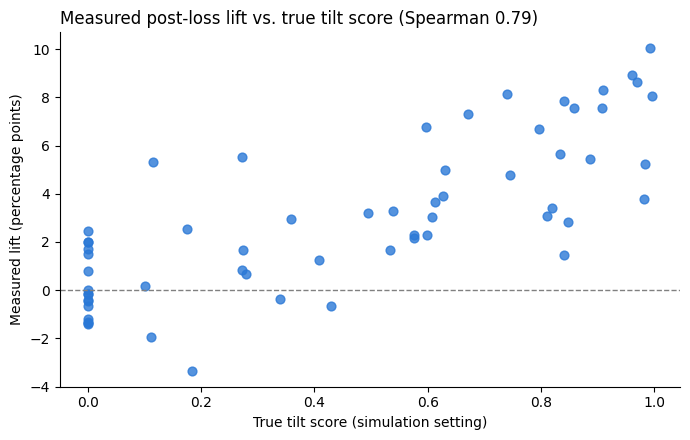

In [13]:
neutral = ~test['after_loss'] & ~test['after_win']
per_player = pd.DataFrame({
    'after_loss_rate': test[test['after_loss']].groupby('player')['flag'].mean(),
    'neutral_rate': test[neutral].groupby('player')['flag'].mean(),
}).join(players[['tilt_score', 'archetype']])
per_player['lift'] = per_player['after_loss_rate'] - per_player['neutral_rate']

rho = per_player[['tilt_score', 'lift']].corr(method='spearman').iloc[0, 1]
auc_p = roc_auc_score(per_player['tilt_score'] > 0, per_player['lift'].fillna(0))
print(f"Spearman correlation (true tilt_score vs measured lift): {rho:.2f}")
print(f"AUC for picking out tilt-prone players (tilt_score > 0): {auc_p:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(per_player['tilt_score'], per_player['lift'] * 100, color='#2a78d6', s=40, alpha=0.8)
ax.axhline(0, color='gray', lw=1, ls='--')
ax.set_xlabel('True tilt score (simulation setting)')
ax.set_ylabel('Measured lift (percentage points)')
ax.set_title(f'Measured post-loss lift vs. true tilt score (Spearman {rho:.2f})', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_sim_players.png', dpi=200); plt.show()

### 9d. The real-data test, with a negative control

The same logistic regression as RQ3 (flag ~ after large loss + after large win). Players with `tilt_score = 0` never
tilt, so their odds ratio **should be about 1**: if the method found an "effect" there, it would be a false finding.

In [14]:
groups = {'all players': test,
          'never tilt (tilt_score = 0)': test[test['tilt_score'] == 0],
          'tilt-prone (tilt_score > 0)': test[test['tilt_score'] > 0]}
rows = []
for name, g in groups.items():
    o_l, p_l, o_w, p_w = after_loss_odds_ratio(g)
    rows.append({'group': name, 'bets': len(g), 'OR after loss': o_l, 'p (loss)': p_l, 'OR after win': o_w, 'p (win)': p_w})
pd.DataFrame(rows).set_index('group').round(3)

,bets,OR after loss,p (loss),OR after win,p (win)
group,,,,,
all players,61458,2.489,0.000,0.856,0.011
never tilt (tilt_score = 0),15119,0.901,0.509,0.971,0.848
tilt-prone (tilt_score > 0),46339,2.907,0.000,0.838,0.008


### 9e. Bet-level breakdown of the current method (s > 2)

How the current score does on individual bets, split three ways:
- **by how tilted the bet really was** (true tilt level T and the average size increase it caused);
- **by street**;
- **by player type**.

`false alarm` = share of non-tilted bets that get flagged.

In [18]:
f2 = test['s'] > 2
y = test['tilted']
print(f"overall: AUC {roc_auc_score(y, test['s']):.3f} | flagged {f2.mean():.1%} | precision {y[f2].mean():.1%} | "
      f"recall {f2[y].mean():.1%} | false alarm {f2[~y].mean():.1%} | base rate {y.mean():.1%}")

level = pd.cut(test['true_T'], [-1, 0.3, 0.6, 1.0, np.inf],
               labels=['not tilted (T < 0.3)', 'mild (0.3–0.6)', 'moderate (0.6–1.0)', 'strong (T > 1)'])
by_level = pd.DataFrame({'bets': level.value_counts(sort=False),
                         'avg size increase': test['tilt_mult'].groupby(level, observed=True).mean() - 1,
                         'share flagged': f2.groupby(level, observed=True).mean()})
display(by_level.round(3))


def bet_metrics(g):
    flag = g['s'] > 2
    return pd.Series({'bets': len(g), 'tilted share': g['tilted'].mean(),
                      'AUC': roc_auc_score(g['tilted'], g['s']),
                      'precision': g['tilted'][flag].mean(), 'recall': flag[g['tilted']].mean(),
                      'false alarm': flag[~g['tilted']].mean()})


display(test.groupby('street_idx').apply(bet_metrics).rename(index={0: 'preflop', 1: 'flop', 2: 'turn', 3: 'river'}).round(3))
display(test.groupby('archetype').apply(bet_metrics).round(3))

overall: AUC 0.583 | flagged 3.1% | precision 35.0% | recall 8.4% | false alarm 2.3% | base rate 12.8%


,bets,avg size increase,share flagged
true_T,,,
not tilted (T < 0.3),53614,0.015,0.023
mild (0.3–0.6),3513,0.164,0.046
moderate (0.6–1.0),2202,0.313,0.080
strong (T > 1),2129,0.663,0.152


,bets,tilted share,AUC,precision,recall,false alarm
street_idx,,,,,,
preflop,43407.0,0.129,0.594,0.436,0.090,0.017
flop,9296.0,0.131,0.556,0.248,0.076,0.035
turn,5295.0,0.119,0.570,0.204,0.067,0.035
river,3460.0,0.113,0.535,0.150,0.059,0.042


,bets,tilted share,AUC,precision,recall,false alarm
archetype,,,,,,
LAG,10721.0,0.164,0.571,0.491,0.089,0.018
Maniac,14533.0,0.173,0.583,0.515,0.081,0.016
Nit,7912.0,0.051,0.578,0.135,0.094,0.032
Station,13088.0,0.154,0.562,0.371,0.073,0.023
TAG,15204.0,0.076,0.632,0.236,0.101,0.027


## 10. How detection depends on tilt strength

The same simulation (smaller, 300 sessions each) at three tilt strengths:
- `TILT_SIZE = 0`: tilted players bet **no bigger on average**. They still size bets more erratically (noise up to
  1.5× wider) and play looser, so some post-loss effect remains, but the score can no longer tell *which* bets are
  tilted (AUC about 0.5).
- `0.35`: the main setting (T = 1 → 1.4× bets).
- `0.7`: strong tilt (T = 1 → 2× bets).

Set `RUN_SWEEP = False` to skip it (it takes about 4 minutes).

In [16]:
RUN_SWEEP = True

if RUN_SWEEP:
    main_tilt_size = TILT_SIZE
    sweep = []
    for ts in [0.0, 0.35, 0.7]:
        TILT_SIZE = ts                        # used inside size()
        d_s, pl_s = simulate(n_players=60, n_sessions=300, seed=1, verbose=False)
        t_s, info_s = run_pipeline(d_s, pl_s)
        o_l, p_l, _, _ = after_loss_odds_ratio(t_s)
        f5 = t_s['s'] >= t_s['s'].quantile(0.95)
        pp = pd.DataFrame({'a': t_s[t_s['after_loss']].groupby('player')['flag'].mean(),
                           'n': t_s[~t_s['after_loss'] & ~t_s['after_win']].groupby('player')['flag'].mean()}).join(pl_s['tilt_score'])
        sweep.append({'TILT_SIZE': ts, 'bet multiplier at T = 1': np.exp(ts),
                      'AUC (personal)': roc_auc_score(t_s['tilted'], t_s['s']),
                      'precision, top 5%': t_s['tilted'][f5].mean(), 'base rate': t_s['tilted'].mean(),
                      'OR after loss': o_l, 'p': p_l,
                      'player Spearman': (pp['a'] - pp['n']).corr(pp['tilt_score'], method='spearman')})
        print(f'TILT_SIZE {ts} done')
    TILT_SIZE = main_tilt_size
    display(pd.DataFrame(sweep).set_index('TILT_SIZE').round(3))

TILT_SIZE 0.0 done
TILT_SIZE 0.35 done
TILT_SIZE 0.7 done


,bet multiplier at T = 1,AUC (personal),"precision, top 5%",base rate,OR after loss,p,player Spearman
TILT_SIZE,,,,,,,
0.00,1.000,0.486,0.112,0.082,1.368,0.002,0.204
0.35,1.419,0.577,0.166,0.076,1.795,0.000,0.530
0.70,2.014,0.654,0.287,0.081,3.494,0.000,0.691


## 11. Limitations

- **Simplified poker.** Agents follow hand-written rules, not real strategy; they don't adapt to opponents.
  The realism check (section 7) shows the data is roughly similar, not identical.
- **Circularity.** The simulated tilt (bigger bets after big losses) is close to what the detector looks for, so
  results here are a *best case* for that kind of tilt. Tilt that shows up only as looser play or more bluffing
  (also simulated) is mostly invisible to a bet-size detector, which is part of why recall is low.
- **Settings are assumptions.** How often players tilt, how strongly, and how fast it fades are chosen, not measured.
  Section 10 shows how the conclusions change with tilt strength.
- So this notebook measures **how well the method can work**, not whether real players tilt. The real-data
  results (post-loss effect, placebo test, same-table check) remain the evidence for that.

## 12. Save

In [17]:
sim.to_parquet('sim_decisions.parquet', index=False)   # every simulated decision, with the hidden truth columns
players.to_csv('sim_players.csv')                       # each simulated player's settings
test.to_parquet('sim_scored.parquet', index=False)      # test bets with scores and truth